# PyTorch — L’essentiel du framework

**Objectifs :**
- comprendre les `Tensor` ;
- utiliser `Autograd` ;
- construire un modèle avec `nn.Module` ;
- définir un `Loss` et un `Optimizer` ;
- écrire une boucle d’apprentissage ;
- distinguer `train()` et `eval()` ;
- utiliser `Dataset` / `DataLoader` ;
- entraîner un exemple de régression et un exemple de classification ;
- sauvegarder et recharger un modèle.

## 0. Préparation

Le notebook fonctionne sur CPU. S’il existe un GPU CUDA, PyTorch pourra l’utiliser automatiquement.

In [111]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.15.0
CUDA disponible: False


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [112]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

Un `Tensor` est la structure de données fondamentale de PyTorch.

In [113]:
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0, 2.0, 3.0])
matrix = torch.tensor([[1.0, 2.0], [3.0, 4.0]])

print("scalar:", scalar, "shape =", scalar.shape)
print("vector:", vector, "shape =", vector.shape)
print("matrix:", matrix, "shape =", matrix.shape)
print("dtype:", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape = torch.Size([])
vector: tensor([1., 2., 3.]) shape = torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape = torch.Size([2, 2])
dtype: torch.float32
ndim: 2


### Manipulation de Tensors

In [114]:
x = torch.arange(12)
print("x =", x)

x2 = x.reshape(3, 4)
print("reshape(3,4):", x2)

print("Colonne 1:", x2[:, 1])
print("Ligne 0:", x2[0, :])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1., 2.]])
print("A @ B =", A @ B)

print("mean(A) =", A.mean())
print("sum(A) =", A.sum())

x = tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
Colonne 1: tensor([1, 5, 9])
Ligne 0: tensor([0, 1, 2, 3])
A @ B = tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A) = tensor(2.5000)
sum(A) = tensor(10.)


## 3. CPU, GPU et `device`

In [115]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cpu
x.device = cpu


## 4. Autograd

`Autograd` calcule automatiquement les dérivées à partir du graphe de calcul.

In [116]:
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

loss.backward()

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", w.grad.item())
print("dLoss/db =", b.grad.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


In [117]:
import torch

x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad=True)
b = torch.tensor(1.0, requires_grad=True)

y = w * x + b
loss = (y - 10) ** 2

dw, db = torch.autograd.grad(loss, (w, b))

print("y =", y.item())
print("loss =", loss.item())
print("dLoss/dw =", dw.item())
print("dLoss/db =", db.item())

y = 7.0
loss = 9.0
dLoss/dw = -12.0
dLoss/db = -6.0


### Vérification analytique

Ici :

\[
y = wx+b
\]

et

\[
L=(y-10)^2
\]

Donc :

\[
\frac{\partial L}{\partial w}=2(y-10)x
\]

\[
\frac{\partial L}{\partial b}=2(y-10)
\]


In [118]:
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

Un neurone linéaire calcule essentiellement :

\[
z = \sum_i w_i x_i + b
\]

In [119]:
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)

print("Sortie:", y)
print("Poids:", model.weight)
print("Biais:", model.bias)

Sortie: tensor([[1.8630]], grad_fn=<AddmmBackward0>)
Poids: Parameter containing:
tensor([[ 0.5388, -0.0616,  0.5243]], requires_grad=True)
Biais: Parameter containing:
tensor([-0.1255], requires_grad=True)


In [120]:
# Visualisation optionnelle du graphe de calcul
try:
    from torchviz import make_dot

    model_viz = nn.Linear(3, 1)
    x_viz = torch.tensor([[1.0, 2.0, 3.0]])
    y_viz = model_viz(x_viz)
    dot = make_dot(y_viz, params=dict(model_viz.named_parameters()))
    dot.render("graphe_operations", format="png", cleanup=True)
    print("Graphe enregistré dans graphe_operations.png")
except (ImportError, OSError) as exc:
    print("Visualisation ignorée (torchviz/Graphviz non disponible) :", exc)


Visualisation ignorée (torchviz/Graphviz non disponible) : No module named 'torchviz'


## 6. Construire un réseau avec `nn.Module`

In [121]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )

    def forward(self, x):
        return self.net(x)

model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


In [122]:
model = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d’activation

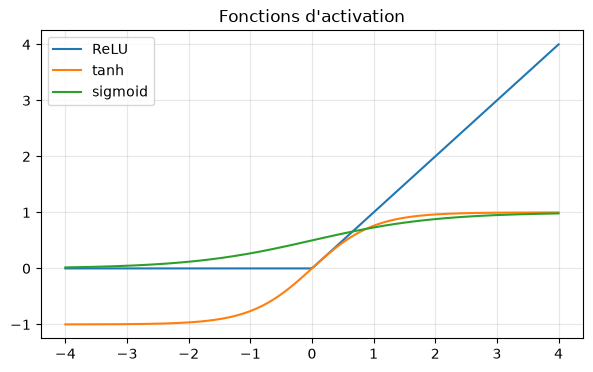

In [123]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7,4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

L’appel `model(X)` déclenche automatiquement `model.forward(X)`.

In [124]:
X = torch.randn(5, 4)
# L’appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

Cas principaux :
- régression : `nn.MSELoss()` ;
- classification multi-classe : `nn.CrossEntropyLoss()` ;
- classification binaire : `nn.BCEWithLogitsLoss()`.

In [125]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

# Classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


## 10. Optimizers

L’optimiseur utilise les gradients pour mettre à jour les paramètres.

In [126]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d’apprentissage

C’est le cœur de PyTorch.

In [127]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500
# Exemple générique
for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 ==0 : 
        print(f"epoch={epoch} loss={loss.item():.4f}")

epoch=0 loss=0.9196
epoch=100 loss=0.0369
epoch=200 loss=0.0001
epoch=300 loss=0.0000
epoch=400 loss=0.0000


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` influencent notamment le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients. Pour l’inférence, on utilise généralement `torch.inference_mode()`.

In [128]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([2., 0., 2., 0., 0., 0., 0., 0., 2., 0.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


## 13. Dataset et DataLoader

In [129]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de :

\[
y = 3x + 2 + bruit
\]

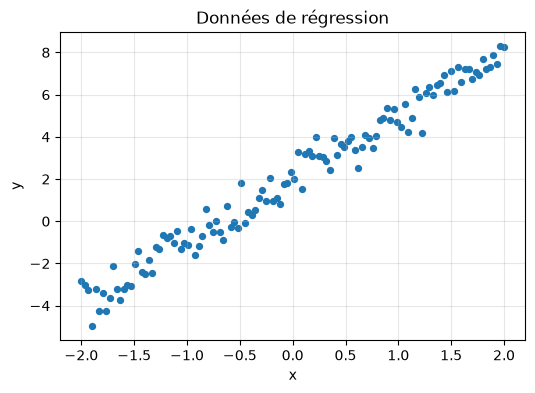

In [130]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [131]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [132]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438418209552765
w appris: 2.9894580841064453
b appris: 2.030014753341675


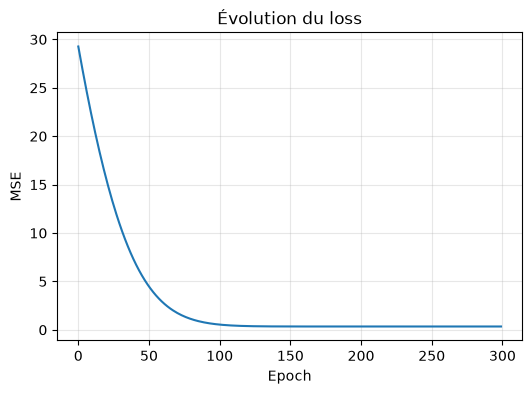

In [133]:
plt.figure(figsize=(6,4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

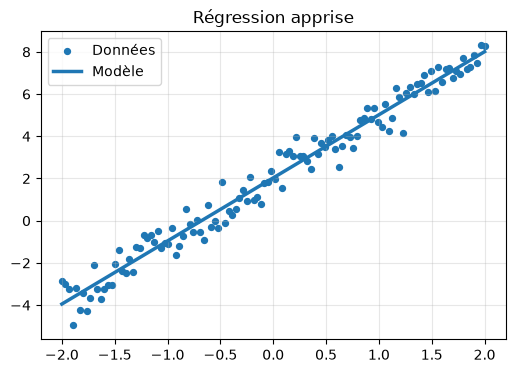

In [134]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6,4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [135]:
ss_res = torch.sum((y - y_hat) ** 2)
ss_tot = torch.sum((y - y.mean()) ** 2)
r2 = 1 - ss_res / ss_tot
print(f"R2 Score = {r2.item():.3f}")


R2 Score = 0.972


# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

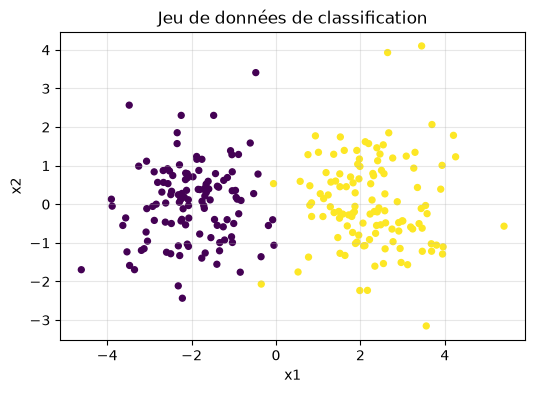

In [136]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6,4))
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [137]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [138]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943692569620907


In [139]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


In [140]:
tp = ((pred == 1) & (y_cls == 1)).sum().item()
tn = ((pred == 0) & (y_cls == 0)).sum().item()
fp = ((pred == 1) & (y_cls == 0)).sum().item()
fn = ((pred == 0) & (y_cls == 1)).sum().item()

accuracy_value = (tp + tn) / (tp + tn + fp + fn)
precision_value = tp / (tp + fp) if tp + fp else 0.0
recall_value = tp / (tp + fn) if tp + fn else 0.0
f1_value = 2 * precision_value * recall_value / (precision_value + recall_value) if precision_value + recall_value else 0.0
confusion_matrix = torch.tensor([[tn, fp], [fn, tp]])

print(f"Accuracy={accuracy_value:.4f}, Recall={recall_value:.4f}, Precision={precision_value:.4f}, F1={f1_value:.4f}")
print("Matrice de confusion :\n", confusion_matrix)


Accuracy=1.0000, Recall=1.0000, Precision=1.0000, F1=1.0000
Matrice de confusion :
 tensor([[120,   0],
        [  0, 120]])


## Visualisation de la frontière de décision

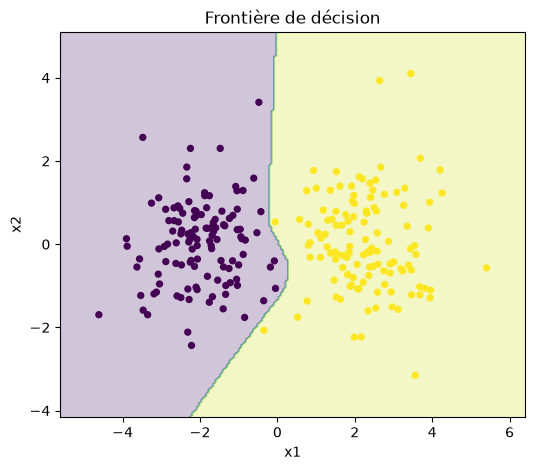

In [141]:
x1_min, x1_max = X_cls[:,0].min()-1, X_cls[:,0].max()+1
x2_min, x2_max = X_cls[:,1].min()-1, X_cls[:,1].max()+1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6,5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:,0], X_cls[:,1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

In [142]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch sont maintenant en place :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste pratiquement la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs ou PINNs.

# Exercices

### Exercice 1 : Régression

Prédire le salaire selon l’ancienneté et le niveau d’expertise

Objectif:

Construire un modèle de régression linéaire multiple pour prédire le salaire mensuel à partir de deux variables :
- Ancienneté : nombre d’années d’expérience.
- Niveau d’expertise : note de 1 à 5.
Le modèle doit apprendre la relation :

Salaire = w_1 * Ancienneté + w_2 * Expertise + b 

Les salaires sont exprimés en dirhams (DH). Les données sont fictives et servent uniquement à l’apprentissage.

1. *Générer les données*

Pour cet exercice, on suppose que les salaires suivent approximativement la règle : Salaire = 4000 + 600 * Ancienneté + 1500 * Expertise} + Bruit
Le bruit représente les variations individuelles non expliquées par les deux variables.

In [143]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Nombre de salariés
n = 300

# Ancienneté : de 0 à 20 ans
anciennete = torch.randint(0, 21, (n, 1)).float()

# Expertise : de 1 à 5
expertise = torch.randint(1, 6, (n, 1)).float()

# Variations aléatoires des salaires
bruit = torch.randn(n, 1) * 500

# Salaire mensuel en DH
salaires = (
    4000
    + 600 * anciennete
    + 1500 * expertise
    + bruit
)

# Matrice des entrées : dimensions (300, 2)
X = torch.cat([anciennete, expertise], dim=1)

# Sortie : dimensions (300, 1)
y = salaires

for i in range(5):
    print(
        f"Ancienneté : {X[i, 0].item():.0f} ans | "
        f"Expertise : {X[i, 1].item():.0f}/5 | "
        f"Salaire : {y[i, 0].item():.2f} DH"
    )

Ancienneté : 15 ans | Expertise : 2/5 | Salaire : 16262.90 DH
Ancienneté : 2 ans | Expertise : 3/5 | Salaire : 10541.39 DH
Ancienneté : 4 ans | Expertise : 3/5 | Salaire : 10948.37 DH
Ancienneté : 19 ans | Expertise : 3/5 | Salaire : 20028.54 DH
Ancienneté : 18 ans | Expertise : 2/5 | Salaire : 18036.38 DH


**Travail demandé — résultats**

- Afficher les dimensions de `X` et `y` et calculer le salaire moyen.
- Tracer le salaire selon l’ancienneté, coloré par niveau d’expertise.


Dimensions de X : torch.Size([300, 2])
Dimensions de y : torch.Size([300, 1])
Salaire moyen : 15010.55 DH


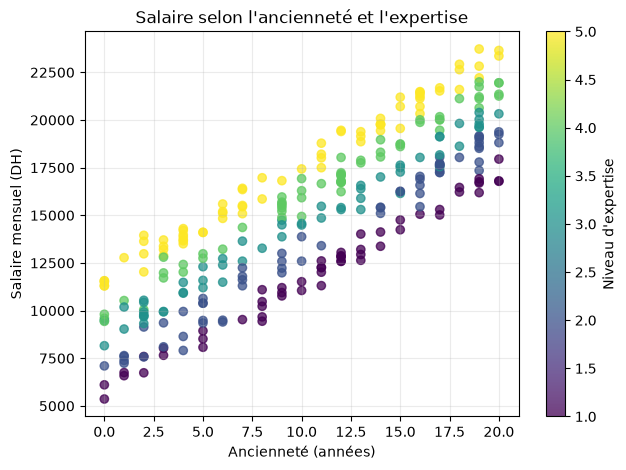

In [144]:
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)
print(f"Salaire moyen : {y.mean().item():.2f} DH")

plt.figure(figsize=(7, 5))
nuage = plt.scatter(
    anciennete.squeeze().numpy(),
    salaires.squeeze().numpy(),
    c=expertise.squeeze().numpy(),
    cmap="viridis",
    alpha=0.75
)
plt.colorbar(nuage, label="Niveau d'expertise")
plt.xlabel("Ancienneté (années)")
plt.ylabel("Salaire mensuel (DH)")
plt.title("Salaire selon l'ancienneté et l'expertise")
plt.grid(True, alpha=0.25)
plt.show()


2. *Séparer et préparer les données*
Utilisez 80 % des données pour l’entraînement et 20 % pour le test.

Pour faciliter l’apprentissage :

standardisez les entrées à partir des statistiques du jeu d’entraînement ;
exprimez les salaires en milliers de DH.

In [145]:
indices = torch.randperm(n)
limite = int(0.8 * n)

train_indices = indices[:limite]
test_indices = indices[limite:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices] / 1000
y_test = y[test_indices] / 1000

# Statistiques calculées uniquement sur le jeu d'entraînement
moyenne = X_train.mean(dim=0, keepdim=True)
ecart_type = X_train.std(dim=0, keepdim=True)

X_train_norm = (X_train - moyenne) / ecart_type
X_test_norm = (X_test - moyenne) / ecart_type

3. *Construire et entraîner le modèle*

In [146]:
# Deux variables d'entrée et une sortie
model = nn.Linear(2, 1)

criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
historique = []

model.train()
for epoch in range(500):
    optimizer.zero_grad()
    predictions = model(X_train_norm)
    loss = criterion(predictions, y_train)
    loss.backward()
    optimizer.step()
    historique.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Époque {epoch + 1} | Perte : {loss.item():.4f}")


Époque 100 | Perte : 0.2391
Époque 200 | Perte : 0.2391
Époque 300 | Perte : 0.2391
Époque 400 | Perte : 0.2391
Époque 500 | Perte : 0.2391


Travail demandé :

- Complétez le modèle et la boucle d’entraînement.
- Tracez l’évolution de la perte :


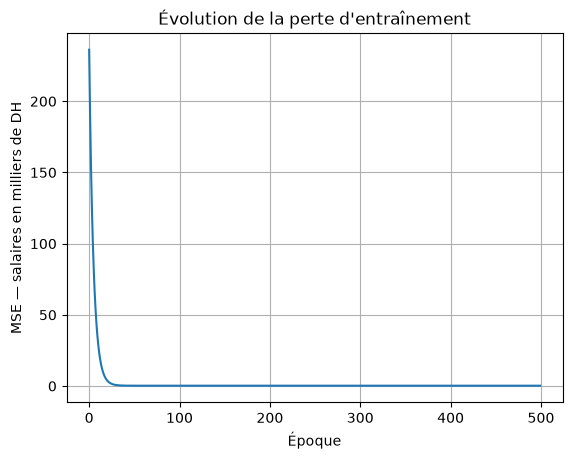

In [147]:
plt.plot(historique)
plt.xlabel("Époque")
plt.ylabel("MSE — salaires en milliers de DH")
plt.title("Évolution de la perte d'entraînement")
plt.grid()
plt.show()

4. Évaluer les prédictions

In [148]:
model.eval()

with torch.no_grad():
    predictions_test = model(X_test_norm)
    predictions_dh = predictions_test * 1000
    salaires_reels_dh = y_test * 1000
    mae = torch.mean(torch.abs(predictions_dh - salaires_reels_dh))

print(f"Erreur absolue moyenne : {mae.item():.2f} DH")


Erreur absolue moyenne : 381.64 DH


Interprétation : une MAE de 400 DH signifie que les prédictions s’écartent, en moyenne, de 400 DH des salaires réels.

5. Prédire le salaire d’un nouveau salarié

Prédisez le salaire d’une personne ayant :

- 7 ans d’ancienneté ;
- un niveau d’expertise de 4/5.

In [149]:
nouveau_salarie = torch.tensor([[7.0, 4.0]])
nouveau_salarie_norm = (nouveau_salarie - moyenne) / ecart_type

model.eval()
with torch.no_grad():
    salaire_predit = model(nouveau_salarie_norm) * 1000

print(f"Salaire estimé : {salaire_predit.item():.2f} DH")


Salaire estimé : 14201.94 DH


Vérification : d’après la règle de génération, le salaire sans bruit est :

4000 + 600 * 7 + 1500 * 4 = 14200 DH

Votre prédiction devrait être proche de cette valeur.

Questions complémentaires :

- À expertise constante, quel est l’effet d’une année d’ancienneté supplémentaire ?
- Pourquoi la perte ne devient-elle pas exactement nulle ?
- Le modèle est-il fiable pour une ancienneté de 40 ans, absente des données d’entraînement ?
- Quel effet aurait une augmentation du bruit sur la précision ?
- Retrouvez les coefficients en unités d’origine à partir des paramètres du modèle entraîné. Ils devraient être proches de 600, 1500 et 4000.

Remarque : traiter l’expertise comme une note numérique suppose que chaque passage d’un niveau au suivant a le même effet sur le salaire. Cette hypothèse simplifie l’exercice, mais doit être vérifiée avec des données réelles.

In [150]:
# Retrouver les coefficients dans les unités d'origine (DH)
poids_norm = model.weight.detach().squeeze()
biais_norm = model.bias.detach().squeeze()
coefficients_dh = 1000 * poids_norm / ecart_type.squeeze()
biais_dh = 1000 * (biais_norm - (poids_norm * moyenne.squeeze() / ecart_type.squeeze()).sum())

print(f"Coefficient ancienneté : {coefficients_dh[0].item():.2f} DH/an")
print(f"Coefficient expertise : {coefficients_dh[1].item():.2f} DH/niveau")
print(f"Biais : {biais_dh.item():.2f} DH")


Coefficient ancienneté : 592.66 DH/an
Coefficient expertise : 1490.75 DH/niveau
Biais : 4090.30 DH


**Réponses aux questions complémentaires**

- À expertise constante, une année supplémentaire augmente le salaire d’environ **600 DH**.
- La perte ne devient pas nulle à cause du bruit aléatoire ajouté aux salaires.
- Une prédiction à 40 ans est une extrapolation hors des données d’entraînement : elle est donc moins fiable.
- Plus de bruit augmente en général la MAE et rend les coefficients appris moins précis.


### Exercice 2 — Classification des fleurs Iris 🌸

Objectif : entraîner un réseau de neurones pour prédire l’espèce d’une fleur à partir de quatre mesures.


**1. Préparation des données**

In [151]:
import torch
from torch import nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)

# Charger les données
iris = load_iris()
X, y = iris.data, iris.target

# Séparer les données : 80 % entraînement, 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Ajuster la normalisation uniquement sur l'entraînement
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convertir en tenseurs
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Dimensions :", X_train.shape, y_train.shape)

Dimensions : torch.Size([120, 4]) torch.Size([120])


**Questions :**

- Que représentent les quatre colonnes de X_train ?
- Pourquoi utilise-t-on torch.long pour les étiquettes ?
- Pourquoi ne faut-il pas ajuster le StandardScaler sur les données de test ?

**2. Construire le réseau**

In [152]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 3)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)


Attention : n’ajoutez pas de Softmax à la sortie. CrossEntropyLoss attend directement les scores bruts, appelés logits.

**3. Entraîner le modèle**

Complétez la boucle d’entraînement. Pour cet exercice, chaque itération utilise toutes les données d’entraînement.

In [153]:
epochs = 200
losses = []

model.train()
for epoch in range(epochs):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = criterion(logits, y_train)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if (epoch + 1) % 20 == 0:
        print(f"Époque {epoch + 1:3d} | Perte : {loss.item():.4f}")


Époque  20 | Perte : 0.3695
Époque  40 | Perte : 0.1923
Époque  60 | Perte : 0.1063
Époque  80 | Perte : 0.0724
Époque 100 | Perte : 0.0590
Époque 120 | Perte : 0.0525
Époque 140 | Perte : 0.0488
Époque 160 | Perte : 0.0463
Époque 180 | Perte : 0.0445
Époque 200 | Perte : 0.0432


**4. Évaluer le classifieur**

Complétez le calcul des prédictions et de l’accuracy, c’est-à-dire la proportion de fleurs correctement classées.

In [154]:
model.eval()

with torch.no_grad():
    logits = model(X_test)
    predictions = logits.argmax(dim=1)
    accuracy = (predictions == y_test).float().mean()

print(f"Accuracy sur le test : {accuracy.item():.1%}")


Accuracy sur le test : 100.0%


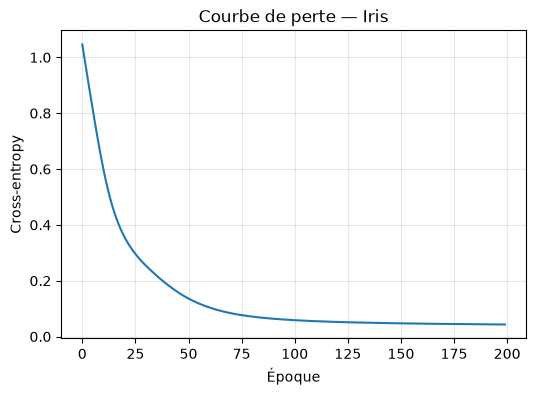

Matrice de confusion Iris :
 tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])
Accuracy du modèle linéaire : 90.0%
Espèce prédite : setosa


In [155]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Époque")
plt.ylabel("Cross-entropy")
plt.title("Courbe de perte — Iris")
plt.grid(True, alpha=0.3)
plt.show()

confusion_iris = torch.zeros(3, 3, dtype=torch.int64)
for vrai, predit in zip(y_test, predictions):
    confusion_iris[vrai, predit] += 1
print("Matrice de confusion Iris :\n", confusion_iris)

# Comparaison avec un modèle sans couche cachée
linear_model = nn.Linear(4, 3)
linear_optimizer = torch.optim.Adam(linear_model.parameters(), lr=0.01)
for _ in range(200):
    linear_optimizer.zero_grad()
    linear_loss = criterion(linear_model(X_train), y_train)
    linear_loss.backward()
    linear_optimizer.step()
linear_model.eval()
with torch.no_grad():
    linear_accuracy = (linear_model(X_test).argmax(1) == y_test).float().mean()
print(f"Accuracy du modèle linéaire : {linear_accuracy.item():.1%}")

nouvelle_fleur = scaler.transform([[5.1, 3.5, 1.4, 0.2]])
nouvelle_fleur = torch.tensor(nouvelle_fleur, dtype=torch.float32)
with torch.no_grad():
    classe = model(nouvelle_fleur).argmax(1).item()
print("Espèce prédite :", iris.target_names[classe])


**Réponses Iris**

- Les quatre colonnes sont la longueur et la largeur du sépale, puis la longueur et la largeur du pétale.
- `CrossEntropyLoss` exige des indices de classe entiers, donc les étiquettes doivent être en `torch.long`.
- Ajuster le scaler sur le test provoquerait une fuite d’information ; le test doit rester entièrement indépendant.


**5- Autres question :**

- Tracez la courbe de perte.
- Affichez une matrice de confusion.
- Comparez ce réseau à un modèle sans couche cachée : nn.Linear(4, 3).
- Prédisez l’espèce d’une nouvelle fleur de mesures [5.1, 3.5, 1.4, 0.2], après l’avoir normalisée avec le même scaler.

### Exercice 3 — Classifier les chiffres MNIST

Objectif : utiliser des mini-lots et évaluer un modèle sur les données de test.


In [156]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

#### Travail demandé : 
- Entraînez le modèle pendant 5 époques.
- Utilisez model.train() pendant l’entraînement.
- Évaluez-le avec model.eval() et torch.no_grad().
- Obtenez les classes prédites avec :
   - predicted_classes = outputs.argmax(dim=1)
   - Calculez mes métriques Accuracy, Recall, Precision et f1-Score sur le jeu de test.
   - Afficher la matrice de confusion
   - Affichez quelques images mal classées.
- Sauvegarder et recharger un modèle : réutiliser un réseau entraîné sans recommencer l’apprentissage.

Attention : CrossEntropyLoss attend les sorties brutes du réseau, sans Softmax, et des étiquettes entières.

In [157]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

for epoch in range(5):
    model.train()
    total_loss = 0.0
    for images_batch, labels_batch in train_loader:
        images_batch, labels_batch = images_batch.to(device), labels_batch.to(device)
        optimizer.zero_grad()
        outputs = model(images_batch)
        loss = criterion(outputs, labels_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images_batch.size(0)
    print(f"Époque {epoch + 1}/5 | Perte : {total_loss / len(train_dataset):.4f}")


Époque 1/5 | Perte : 0.3542
Époque 2/5 | Perte : 0.1669
Époque 3/5 | Perte : 0.1165
Époque 4/5 | Perte : 0.0887
Époque 5/5 | Perte : 0.0698


In [158]:
model.eval()
all_predictions, all_labels, misclassified = [], [], []

with torch.no_grad():
    for images_batch, labels_batch in test_loader:
        outputs = model(images_batch.to(device))
        predicted_classes = outputs.argmax(dim=1).cpu()
        all_predictions.append(predicted_classes)
        all_labels.append(labels_batch)

        wrong = predicted_classes != labels_batch
        for image, vrai, predit in zip(images_batch[wrong], labels_batch[wrong], predicted_classes[wrong]):
            if len(misclassified) < 10:
                misclassified.append((image, vrai.item(), predit.item()))

all_predictions = torch.cat(all_predictions)
all_labels = torch.cat(all_labels)
confusion_dense = torch.zeros(10, 10, dtype=torch.int64)
for vrai, predit in zip(all_labels, all_predictions):
    confusion_dense[vrai, predit] += 1

tp = confusion_dense.diag().float()
precision = (tp / confusion_dense.sum(0).clamp(min=1)).mean()
recall = (tp / confusion_dense.sum(1).clamp(min=1)).mean()
f1_par_classe = 2 * (tp / confusion_dense.sum(0).clamp(min=1)) * (tp / confusion_dense.sum(1).clamp(min=1))
f1_par_classe /= ((tp / confusion_dense.sum(0).clamp(min=1)) + (tp / confusion_dense.sum(1).clamp(min=1))).clamp(min=1e-12)
accuracy = (all_predictions == all_labels).float().mean()

print(f"Accuracy : {accuracy.item():.4f}")
print(f"Precision macro : {precision.item():.4f}")
print(f"Recall macro : {recall.item():.4f}")
print(f"F1-score macro : {f1_par_classe.mean().item():.4f}")
print("Matrice de confusion :\n", confusion_dense)


Accuracy : 0.9755
Precision macro : 0.9753
Recall macro : 0.9753
F1-score macro : 0.9753
Matrice de confusion :
 tensor([[ 969,    0,    1,    1,    1,    1,    1,    2,    3,    1],
        [   0, 1124,    3,    1,    0,    1,    1,    1,    4,    0],
        [   4,    1, 1005,    0,    3,    0,    3,    8,    8,    0],
        [   0,    0,    2,  985,    0,    4,    1,    6,    5,    7],
        [   3,    0,    3,    1,  958,    1,    3,    3,    2,    8],
        [   2,    0,    0,    8,    2,  867,    4,    1,    4,    4],
        [   7,    3,    2,    1,    4,    5,  933,    0,    3,    0],
        [   1,    3,    8,    3,    1,    0,    0, 1004,    2,    6],
        [   4,    0,    1,    7,    4,    6,    2,    6,  937,    7],
        [   2,    4,    0,    6,   13,    3,    1,    5,    2,  973]])


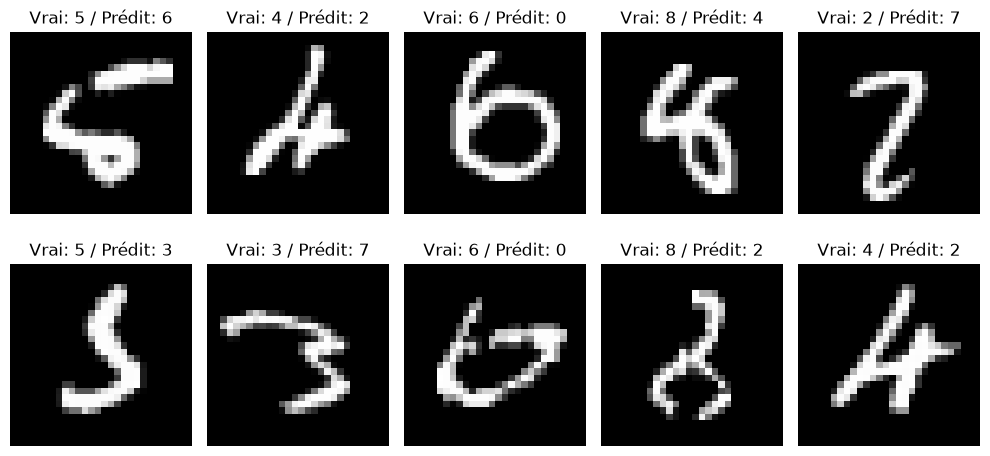

Modèle MNIST dense sauvegardé et rechargé.


In [159]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, (image, vrai, predit) in zip(axes.ravel(), misclassified):
    ax.imshow(image.squeeze().numpy(), cmap="gray")
    ax.set_title(f"Vrai: {vrai} / Prédit: {predit}")
    ax.axis("off")
plt.tight_layout()
plt.show()

torch.save(model.state_dict(), "mnist_dense.pth")
reloaded_model = nn.Sequential(
    nn.Flatten(), nn.Linear(28 * 28, 128), nn.ReLU(), nn.Linear(128, 10)
).to(device)
reloaded_model.load_state_dict(torch.load("mnist_dense.pth", map_location=device, weights_only=True))
reloaded_model.eval()
print("Modèle MNIST dense sauvegardé et rechargé.")


### Exercice 4 — Classification MNIST avec un CNN

Objectif : construire un réseau de neurones convolutif (CNN) pour reconnaître les chiffres manuscrits de 0 à 9.

MNIST contient 60 000 images d’entraînement et 10 000 images de test, en niveaux de gris, de taille 28 × 28 pixels.

**1. Chargement des données**

In [160]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil :", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)

test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=64, shuffle=True
)

test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False
)

images, labels = next(iter(train_loader))

print("Images :", images.shape)  # [64, 1, 28, 28]
print("Labels :", labels.shape)  # [64]

Appareil : cpu
Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])


**Questions :**

- Que représentent les quatre dimensions du tenseur images ?
- Pourquoi mélanger les données d’entraînement avec shuffle=True ?

**2. Visualiser quelques images**

Complétez l’affichage des étiquettes :

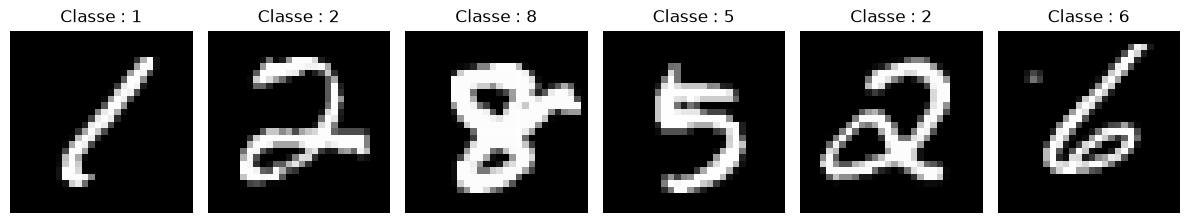

In [161]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    image = images[i, 0] * 0.3081 + 0.1307
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


**3. Construire le CNN**

Implémentez cette architecture :

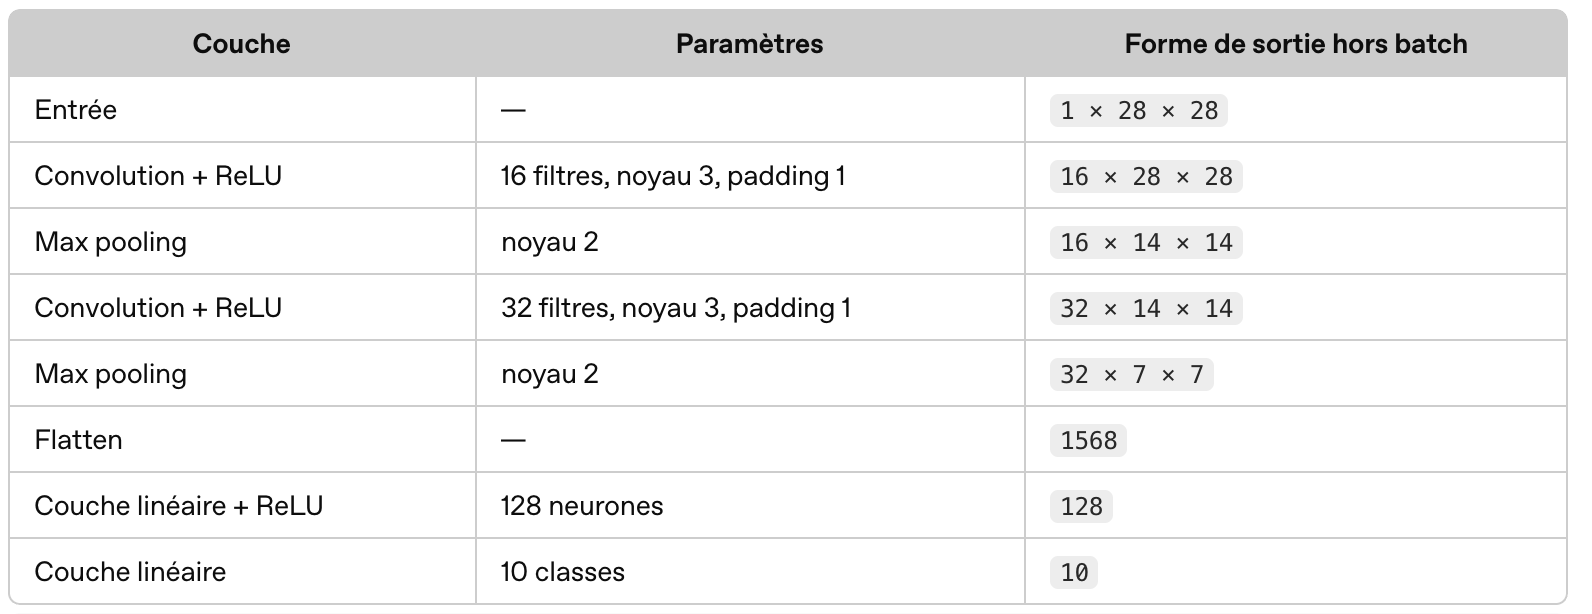

In [162]:
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = MNISTClassifier().to(device)
with torch.no_grad():
    output = model(images.to(device))

assert output.shape == (images.size(0), 10)
print("Sortie :", output.shape)


Sortie : torch.Size([64, 10])


Après deux max-poolings de facteur 2, la taille spatiale passe de 28 × 28 à 14 × 14 puis à 7 × 7. La seconde convolution produit 32 cartes de caractéristiques : la couche linéaire reçoit donc **32 × 7 × 7 = 1568 valeurs** par image.


**Question :** pourquoi la première couche linéaire reçoit-elle 32 × 7 × 7 valeurs ?

Attention : n’ajoutez pas de Softmax au modèle. CrossEntropyLoss attend les scores bruts, appelés logits.

**4. Entraîner le réseau**

In [163]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 3
loss_history = []

for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)

    average_loss = total_loss / len(train_dataset)
    loss_history.append(average_loss)
    print(f"Époque {epoch + 1}/{epochs} | Perte : {average_loss:.4f}")


Époque 1/3 | Perte : 0.1867
Époque 2/3 | Perte : 0.0594
Époque 3/3 | Perte : 0.0429


**5. Évaluer sur le jeu de test**

In [164]:
model.eval()
correct = 0
total = 0
cnn_errors = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        wrong = predictions != labels
        for image, vrai, predit in zip(images[wrong], labels[wrong], predictions[wrong]):
            if len(cnn_errors) < 10:
                cnn_errors.append((image.cpu(), vrai.item(), predit.item()))

accuracy = correct / total
print(f"Accuracy sur le test : {accuracy:.2%}")


Accuracy sur le test : 99.16%


**Indices :**

- argmax(dim=1) sélectionne une classe pour chaque image ;
(predictions == labels).sum().item() compte les prédictions correctes.

- Résultat attendu : une accuracy généralement supérieure à 97 % après quelques époques, sans garantie exacte.

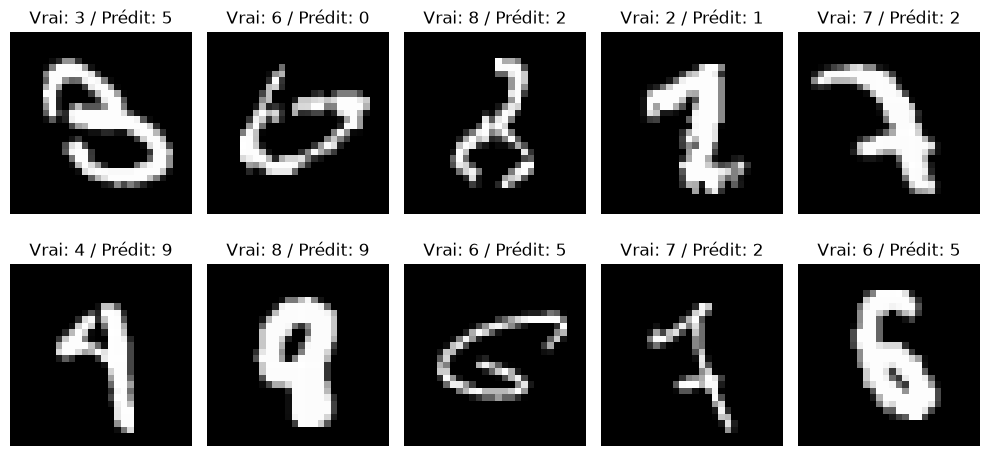

Paramètres sauvegardés dans mnist_cnn.pth


In [165]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, (image, vrai, predit) in zip(axes.ravel(), cnn_errors):
    image = image.squeeze() * 0.3081 + 0.1307
    ax.imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Vrai: {vrai} / Prédit: {predit}")
    ax.axis("off")
plt.tight_layout()
plt.show()

torch.save(model.state_dict(), "mnist_cnn.pth")
print("Paramètres sauvegardés dans mnist_cnn.pth")


**Autres questions :**

- Affichez 10 images mal classées, avec leur vraie classe et la prédiction.
- Ajoutez une couche Dropout avant la dernière couche linéaire.
- Sauvegardez les paramètres avec torch.save(model.state_dict(), "mnist_cnn.pth").